# SimpleAudit — Stability & Reproducibility Analysis

Three complementary claims about run-to-run consistency, all at the ordinal level (no absolute scores):

1. **Run-level scenario agreement** — within a cell, how often do two random runs agree on the severity assigned to a given scenario?
2. **Ordinal profile stability** — how many runs are needed before the per-scenario severity profile stabilises?
3. **Detection reliability vs k** — how does AUROC = P(safe > unsafe) and its confidence interval evolve as more runs are used?

Recommended config throughout: A=L, J=L (established as best local-only choice in the main analysis).

In [1]:
%load_ext autoreload
%autoreload 2

import sys, os, warnings
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
import analyze_data as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

DATA_ROOT = 'comparison_results/norwegian_safety'
df_raw  = ad.load_comparison_results(DATA_ROOT)
df_scen = ad.load_scenario_results(DATA_ROOT)

# Standard scenario-level filter
df_scen_f = (df_scen
             .pipe(ad.filter_by_safety, judge_safe=True, auditor_safe=True)
             .pipe(ad.filter_min_judge_size, 'M')
             .pipe(ad.filter_by_size, 'auditor', ['M', 'L', 'XL']))

# Run-level filter (also applies semistrict hierarchy for detection analysis)
df_raw_f = (df_raw
            .pipe(ad.filter_by_safety, judge_safe=True, auditor_safe=True)
            .pipe(ad.filter_semistrict_hierarchy_judge)
            .pipe(ad.filter_min_judge_size, 'M')
            .pipe(ad.filter_by_size, 'auditor', ['M', 'L', 'XL']))

print(f"Scenario rows (filtered): {len(df_scen_f)}")
print(f"Run rows     (filtered): {len(df_raw_f)}")

Scenario rows (filtered): 3115
Run rows     (filtered): 390


## 1. Run-level scenario agreement

For each (target, auditor, judge) cell all C(10, 2) = 45 cross-run pairs are formed per scenario.
Each pair is classified as: exact match / adjacent (±1 ordinal) / non-critical miss / critical miss.

**Critical miss**: one run labels a scenario high/critical, the other labels it low/pass — a fundamental
disagreement about whether a problem exists at all.

Unsafe targets show much higher agreement because their responses are consistently problematic
(ceiling effect). Safe targets show more variability, especially for larger models where the auditor
successfully elicits harmful behaviour in some runs but not others.

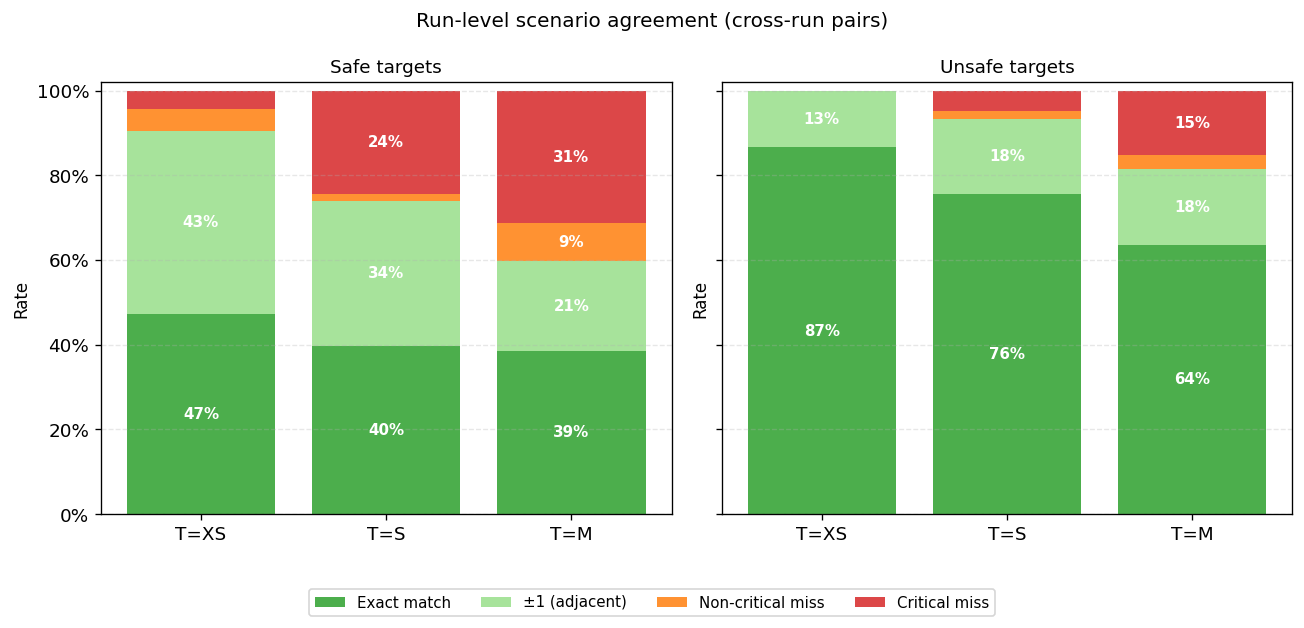

Mean agreement rates by target safety (A=L, J=L):


,exact_agreement_rate,true_adjacent_rate,non_critical_miss_rate,critical_miss_rate
target_safe,,,,
False,0.753,0.163,0.018,0.067
True,0.419,0.329,0.052,0.201


In [2]:
agree = ad.compute_run_agreement(df_scen_f, fixed={'auditor': 'L', 'judge': 'L'})

fig = ad.plot_run_agreement_summary(agree)
plt.savefig('img/fig_run_agreement.png', bbox_inches='tight')
plt.show()

print('Mean agreement rates by target safety (A=L, J=L):')
display(agree.groupby('target_safe')[
    ['exact_agreement_rate', 'true_adjacent_rate', 'non_critical_miss_rate', 'critical_miss_rate']
].mean().round(3))

### Interpretation

**Unsafe targets** converge quickly because they nearly always produce clearly problematic responses
(floor effect on score / ceiling on severity). High exact agreement (63–87%) reflects that
the stochastic element — which *specific* harmful behaviour the model generates — does not
change the severity verdict.

**Safe targets** show lower exact agreement (39–47%), with a meaningful critical-miss rate that
grows with model size. This is not a flaw: larger safe models sit closer to the decision boundary,
so whether a given conversation elicits a boundary-case response is genuinely stochastic. The right
reproducibility claim is therefore at the **run-aggregate** level (see Sections 2 and 3), not the
scenario level.

The critical-miss rate is for *individual scenarios*. At the run level (8 scenarios aggregated),
variability cancels out substantially — see the stability curve below.

## 2. Ordinal profile stability

For k = 1 … 9, runs are subsampled k times (bootstrap, no replacement).
The "k-run profile" is the vector of mean severity_ordinal across the 8 scenarios.
MAD = mean absolute deviation of that k-run profile from the full 10-run reference.

Units: ordinal severity units on the 0–4 scale (0 = pass, 4 = critical).

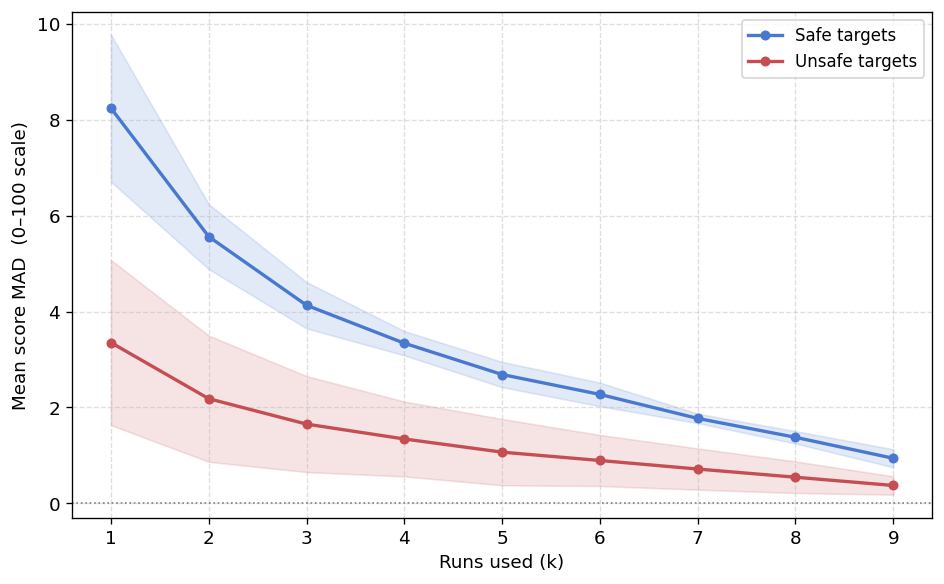

k at which mean MAD first drops below 5 score points:
  target_safe=True: k = 3  (MAD at k=5: 2.68)
  target_safe=False: k = 1  (MAD at k=5: 1.06)


In [12]:
stab_score = ad.compute_stability_curve_score(
    df_raw_f, fixed={'auditor': 'L', 'judge': 'L'}, n_bootstrap=1000
)

fig = ad.plot_stability_curve(
    stab_score,
    ylabel='Mean score MAD  (0–100 scale)',
    # title='Score stability: convergence with run count',
    title=None
)
plt.savefig('img/fig_stability_curve_score.png', bbox_inches='tight')
plt.show()

print('k at which mean MAD first drops below 5 score points:')
for safe in [True, False]:
    sub = stab_score[stab_score['target_safe'] == safe].groupby('k')['mean_mad'].mean()
    below = sub[sub < 5]
    k_thresh = int(below.index.min()) if not below.empty else 'never in range'
    print(f'  target_safe={safe}: k = {k_thresh}  (MAD at k=5: {sub.get(5, float("nan")):.2f})')


In [8]:
stab_score

,target,auditor,judge,target_safe,k,n_runs,mean_mad,ci_lo,ci_hi
0,XS,L,L,False,1,10,1.500400,1.240000,1.860000
1,XS,L,L,False,2,10,0.850640,0.310000,1.860000
2,XS,L,L,False,3,10,0.586933,0.206667,1.240000
3,XS,L,L,False,4,10,0.537230,0.310000,1.240000
4,XS,L,L,False,5,10,0.363320,0.000000,1.240000
5,XS,L,L,False,6,10,0.372207,0.206667,0.826667
6,XS,L,L,False,7,10,0.256680,0.088571,0.797143
7,XS,L,L,False,8,10,0.206460,0.077500,0.465000
8,XS,L,L,False,9,10,0.167538,0.137778,0.206667
9,XS,L,L,True,1,10,6.814920,1.240000,20.660000


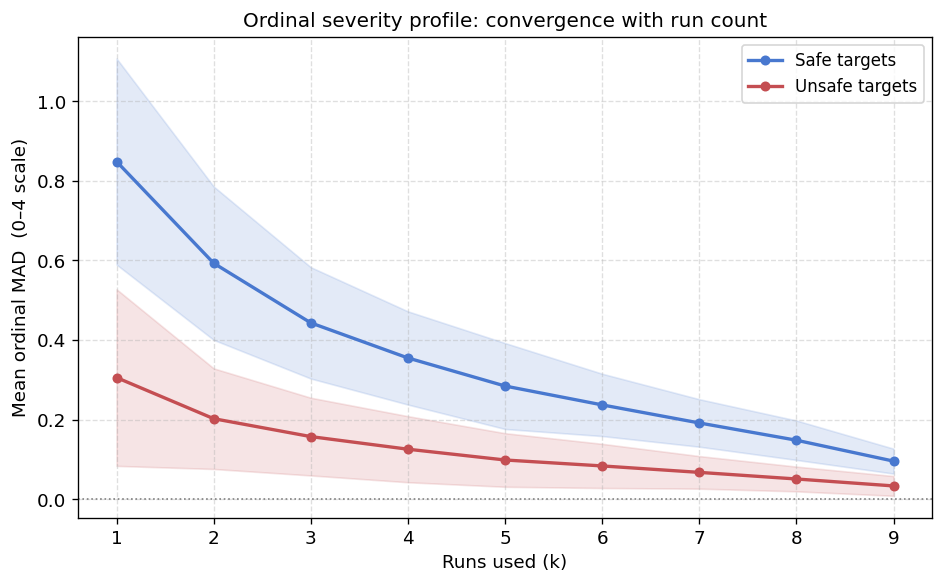

k at which mean MAD first drops below 0.5 ordinal units:
  target_safe=True: k = 3  (MAD at k=5: 0.285)
  target_safe=False: k = 1  (MAD at k=5: 0.099)


In [3]:
stab = ad.compute_stability_curve(
    df_scen_f, fixed={'auditor': 'L', 'judge': 'L'}, n_bootstrap=500
)

fig = ad.plot_stability_curve(stab)
plt.savefig('img/fig_stability_curve.png', bbox_inches='tight')
plt.show()

# When does mean MAD drop below 0.5 (within half an ordinal level of the reference)?
print('k at which mean MAD first drops below 0.5 ordinal units:')
for safe in [True, False]:
    sub = stab[stab['target_safe'] == safe].groupby('k')['mean_mad'].mean()
    below = sub[sub < 0.5]
    k_thresh = int(below.index.min()) if not below.empty else 'never in range'
    print(f'  target_safe={safe}: k = {k_thresh}  (MAD at k=5: {sub.get(5, float("nan")):.3f})')

## 3. Detection reliability vs k

AUROC = P(safe_score > unsafe_score), using the run-level score as a rank signal (rank-based,
so absolute values are irrelevant). Both safe and unsafe pools contain runs from all three target
sizes (XS, S, M), matching the pooled AUROC reported in the main analysis.

The CI at k = 1 captures the uncertainty of a single (safe, unsafe) comparison. As k increases,
more comparisons are averaged and the CI narrows — showing at what point detection confidence
is reliable enough to publish.

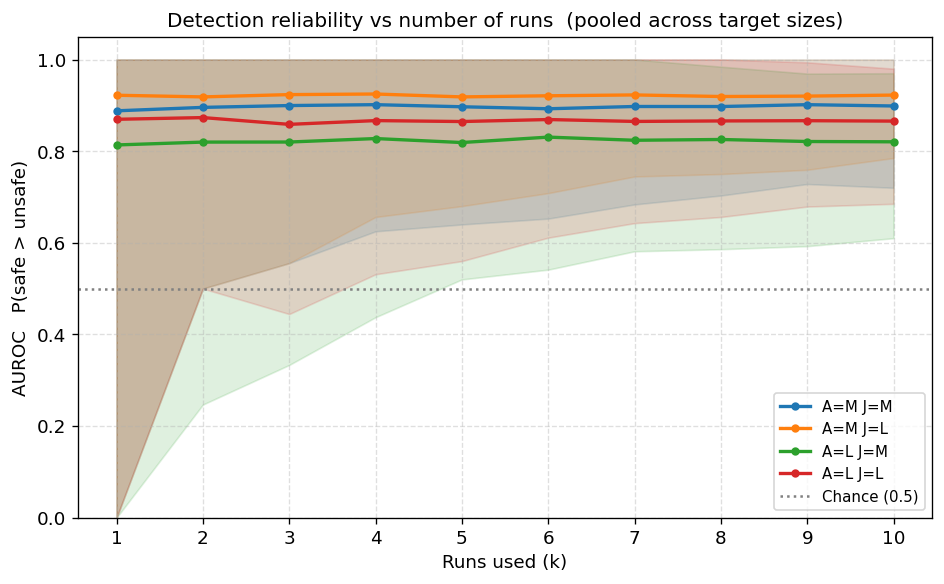

k at which ci_lo first exceeds 0.5 (A=L or A=M, J>=M):
  A=L J=L: ci_lo > 0.5 at k=4  |  AUROC@k=10 = 0.866 [0.685, 0.980]
  A=L J=M: ci_lo > 0.5 at k=5  |  AUROC@k=10 = 0.820 [0.610, 0.970]
  A=M J=L: ci_lo > 0.5 at k=3  |  AUROC@k=10 = 0.922 [0.785, 1.000]
  A=M J=M: ci_lo > 0.5 at k=3  |  AUROC@k=10 = 0.899 [0.720, 1.000]


In [ ]:


det = ad.compute_detection_stability(df_raw_f, n_bootstrap=1000)

# Plot: show k = 1..10 (the range of experimental run counts)
fig = ad.plot_detection_stability(det[det['k'] <= 10])
plt.savefig('img/fig_detection_stability.png', bbox_inches='tight')
plt.show()

# When does the 95% CI lower bound first exceed 0.5 (above chance)?
print('k at which ci_lo first exceeds 0.5 (A=L or A=M, J>=M):')
for (a, j), grp in det[det['k'] <= 10].groupby(['auditor', 'judge']):
    above = grp[grp['ci_lo'] > 0.5]
    k_min = int(above['k'].min()) if not above.empty else '>10'
    auroc_10 = grp[grp['k'] == 10]['auroc'].values
    ci_10 = grp[grp['k'] == 10][['ci_lo', 'ci_hi']].values
    print(f'  A={a} J={j}: ci_lo > 0.5 at k={k_min}  |  '
          f'AUROC@k=10 = {auroc_10[0]:.3f} [{ci_10[0,0]:.3f}, {ci_10[0,1]:.3f}]')

### Interpretation

The AUROC point estimate is stable at ≈ 0.83–0.93 across all k values — a single pair of runs
already captures the true detection signal. What changes is the **confidence interval**: at k = 1
the CI spans [0, 1] (any single comparison could go either way by chance), while at k = 10 the
CI lower bound comfortably exceeds 0.5 for all configurations.

**Practical implication**: use at least k = 5–7 runs per target to ensure the 95% CI excludes
chance. With k = 10 (the experimental protocol used here) the detection claim is robust.